In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import requests
from io import StringIO
import os
import networkx as nx
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df=pd.read_csv(r'nifty500_adjusted_close.csv')
df

,Date,360ONE.NS,AADHARHFC.NS,AARTIIND.NS,AAVAS.NS,ABB.NS,ABBOTINDIA.NS,ABCAPITAL.NS,ABDL.NS,ABREL.NS,...,WIPRO.NS,WOCKPHARMA.NS,YESBANK.NS,ZEEL.NS,ZENSARTECH.NS,ZENTEC.NS,ZFCVINDIA.NS,ZYDUSLIFE.NS,ZYDUSWELL.NS,ECLERX.NS
0,2023-11-17,525.951538,NaN,523.548340,1444.400024,4163.793457,22444.017578,170.949997,NaN,1222.461670,...,182.841507,326.450012,20.799999,233.531769,494.268555,720.624756,2702.883301,627.211243,307.292084,1205.938965
1,2023-11-20,526.047791,NaN,513.956970,1503.349976,4223.991211,22776.798828,171.149994,NaN,1221.317261,...,185.061157,330.799988,20.150000,231.159454,505.148254,756.633545,2741.984619,626.669312,305.505249,1197.174194
2,2023-11-21,530.234192,NaN,517.932678,1525.949951,4222.338867,22752.859375,171.649994,NaN,1236.840576,...,185.269226,337.549988,19.700001,238.893219,521.042114,782.368347,2704.833496,629.674622,310.855957,1167.358276
3,2023-11-22,519.695923,NaN,517.932678,1483.650024,4114.577148,22708.826172,170.949997,NaN,1226.591431,...,185.084274,332.149994,19.200001,236.568329,508.270264,753.840576,2628.440674,632.630554,308.403992,1312.091919
4,2023-11-23,519.984619,NaN,526.530151,1488.150024,4139.987793,22691.962891,171.000000,NaN,1189.872681,...,186.124725,343.299988,20.150000,237.090256,510.919220,753.541382,2681.557129,622.333862,311.203369,1323.653687
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
735,2026-11-11,1170.000000,441.649994,483.250000,1119.599976,6963.000000,26110.000000,396.000000,736.500000,1087.500000,...,197.990005,2034.599976,17.240000,70.860001,553.450012,1761.199951,2336.199951,1199.500000,466.750000,1530.000000
736,2026-11-12,1190.900024,434.450012,483.899994,1138.199951,6923.000000,26600.000000,419.500000,758.000000,1198.000000,...,196.199997,2054.000000,17.690001,73.500000,559.750000,1754.800049,2313.899902,1206.000000,471.000000,1549.400024
737,2026-11-13,1176.800049,432.500000,481.950012,1123.500000,7054.500000,26440.000000,408.000000,757.700012,1203.000000,...,194.600006,2027.199951,17.420000,72.150002,549.549988,1743.699951,2332.399902,1189.900024,469.950012,1578.300049
738,2026-11-16,1179.000000,424.000000,474.500000,1114.900024,6895.000000,25980.000000,408.500000,784.250000,1216.099976,...,193.539993,2004.500000,18.020000,71.660004,539.099976,1732.300049,2207.500000,1192.000000,466.149994,1567.900024


## Cleaning the data frame and calculating the log returns.

In [7]:
df.columns

Index(['Date', '360ONE.NS', 'AADHARHFC.NS', 'AARTIIND.NS', 'AAVAS.NS',
       'ABB.NS', 'ABBOTINDIA.NS', 'ABCAPITAL.NS', 'ABDL.NS', 'ABREL.NS',
       ...
       'WIPRO.NS', 'WOCKPHARMA.NS', 'YESBANK.NS', 'ZEEL.NS', 'ZENSARTECH.NS',
       'ZENTEC.NS', 'ZFCVINDIA.NS', 'ZYDUSLIFE.NS', 'ZYDUSWELL.NS',
       'ECLERX.NS'],
      dtype='str', length=502)

In [8]:
# Count missing values in each column
print(df.isna().sum())

# Count non-finite values in numeric columns
print(np.isfinite(df.select_dtypes(include=np.number)).sum())

Date              0
360ONE.NS         1
AADHARHFC.NS    118
AARTIIND.NS       0
AAVAS.NS          0
               ... 
ZENTEC.NS         0
ZFCVINDIA.NS      0
ZYDUSLIFE.NS      0
ZYDUSWELL.NS      0
ECLERX.NS         0
Length: 502, dtype: int64
360ONE.NS       739
AADHARHFC.NS    622
AARTIIND.NS     740
AAVAS.NS        740
ABB.NS          740
               ... 
ZENTEC.NS       740
ZFCVINDIA.NS    740
ZYDUSLIFE.NS    740
ZYDUSWELL.NS    740
ECLERX.NS       740
Length: 501, dtype: int64


In [9]:
prices = df.drop(columns=['Date']).copy()
print("Percentage of missing values in each column:")
missing_pct = prices.isna().mean() * 100

missing_summary = missing_pct.sort_values(ascending=False)

print(missing_summary.head(20))
# Remove stocks with more than 20% missing prices
prices = prices.loc[:, missing_pct <= 20]
# calc log returns on the remaining prices.
log_returns = np.log(prices / prices.shift(1))

Percentage of missing values in each column:
BAGMANE.NS       100.000000
DUMMYHEG.NS      100.000000
VAML.NS           85.540541
VOGL.NS           85.540541
VISL.NS           85.540541
VEDPOWER.NS       85.540541
CMPDI.NS          78.783784
CLEANMAX.NS       76.351351
FRACTAL.NS        75.000000
BHARATCOAL.NS     72.432432
ICICIAMC.NS       69.729730
MEESHO.NS         68.783784
TENNIND.NS        66.756757
PWL.NS            66.621622
EMMVEE.NS         66.621622
PINELABS.NS       66.351351
TMCV.NS           66.081081
GROWW.NS          66.081081
LENSKART.NS       65.810811
PIRAMALFIN.NS     65.675676
dtype: float64


In [10]:
# Check missing returns
missing_returns = log_returns.isna().sum().sort_values(ascending=False)

print(missing_returns.head(20))

TBOTEK.NS        119
AADHARHFC.NS     119
AIIL.NS          104
BHARTIHEXA.NS     98
FORCEMOT.NS       43
JYOTICNC.NS       41
AZAD.NS           28
INOXINDIA.NS      26
DOMS.NS           23
TATATECH.NS        9
IREDA.NS           8
RRKABEL.NS         5
AEGISLOG.NS        5
BIRET.NS           4
EMBASSY.NS         4
360ONE.NS          3
GALLANTT.NS        3
VIJAYA.NS          3
CIEINDIA.NS        3
HONASA.NS          3
dtype: int64


In [11]:
# calculate the percentage of missing returns for each stock
missing_pct = (log_returns.isna().mean() * 100).sort_values(ascending=False)

print(missing_pct.head(20))

TBOTEK.NS        16.081081
AADHARHFC.NS     16.081081
AIIL.NS          14.054054
BHARTIHEXA.NS    13.243243
FORCEMOT.NS       5.810811
JYOTICNC.NS       5.540541
AZAD.NS           3.783784
INOXINDIA.NS      3.513514
DOMS.NS           3.108108
TATATECH.NS       1.216216
IREDA.NS          1.081081
RRKABEL.NS        0.675676
AEGISLOG.NS       0.675676
BIRET.NS          0.540541
EMBASSY.NS        0.540541
360ONE.NS         0.405405
GALLANTT.NS       0.405405
VIJAYA.NS         0.405405
CIEINDIA.NS       0.405405
HONASA.NS         0.405405
dtype: float64


In [12]:
# keeping only those stocks with less than or equal to 20% missing returns
valid_stocks = missing_pct[missing_pct <= 20].index
log_returns_clean = log_returns[valid_stocks].copy()

In [13]:
# finding the correlation matrix to form the edges of the network graph
correlation_matrix = log_returns.corr(method='pearson', min_periods=60) #min_periods=60 ensures that we only consider pairs of stocks with at least 60 overlapping observations for correlation calculation.
correlation_matrix

,360ONE.NS,AADHARHFC.NS,AARTIIND.NS,AAVAS.NS,ABB.NS,ABBOTINDIA.NS,ABCAPITAL.NS,ABREL.NS,ABSLAMC.NS,ACC.NS,...,WIPRO.NS,WOCKPHARMA.NS,YESBANK.NS,ZEEL.NS,ZENSARTECH.NS,ZENTEC.NS,ZFCVINDIA.NS,ZYDUSLIFE.NS,ZYDUSWELL.NS,ECLERX.NS
360ONE.NS,1.000000,0.190714,0.286399,0.180143,0.248905,0.138914,0.338036,0.264475,0.319503,0.316819,...,0.187768,0.243021,0.265378,0.165563,0.242973,0.287051,0.135497,0.191500,0.170635,0.211072
AADHARHFC.NS,0.190714,1.000000,0.287039,0.246988,0.229867,0.075074,0.286035,0.242713,0.275919,0.310282,...,0.142451,0.198603,0.219113,0.183805,0.213595,0.223387,0.136333,0.155081,0.158308,0.198897
AARTIIND.NS,0.286399,0.287039,1.000000,0.221471,0.324795,0.207786,0.391984,0.315701,0.351686,0.400848,...,0.226618,0.313734,0.358710,0.312935,0.266616,0.305426,0.211901,0.368520,0.199211,0.219471
AAVAS.NS,0.180143,0.246988,0.221471,1.000000,0.217833,0.132942,0.327512,0.241677,0.238452,0.332604,...,0.125029,0.197653,0.225174,0.135783,0.195405,0.174186,0.148523,0.140825,0.173427,0.165425
ABB.NS,0.248905,0.229867,0.324795,0.217833,1.000000,0.132496,0.325999,0.315109,0.313149,0.387256,...,0.153552,0.224041,0.322687,0.200261,0.163136,0.300715,0.139278,0.280403,0.175010,0.142169
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZENTEC.NS,0.287051,0.223387,0.305426,0.174186,0.300715,0.083710,0.270166,0.264916,0.207856,0.230175,...,0.076806,0.229099,0.234099,0.244868,0.245592,1.000000,0.143926,0.159108,0.191103,0.209899
ZFCVINDIA.NS,0.135497,0.136333,0.211901,0.148523,0.139278,0.081544,0.156964,0.124647,0.160025,0.184584,...,0.079669,0.186929,0.159200,0.076087,0.062410,0.143926,1.000000,0.110808,0.088938,0.088923
ZYDUSLIFE.NS,0.191500,0.155081,0.368520,0.140825,0.280403,0.235103,0.293380,0.230119,0.223963,0.231547,...,0.166889,0.258318,0.228148,0.195217,0.210888,0.159108,0.110808,1.000000,0.165250,0.118366
ZYDUSWELL.NS,0.170635,0.158308,0.199211,0.173427,0.175010,0.044174,0.208206,0.190185,0.201579,0.213437,...,0.090362,0.221995,0.205482,0.151773,0.222532,0.191103,0.088938,0.165250,1.000000,0.161402


## Creating an adjacency matrix

In [37]:
# Create an unweighted adjacency matrix
threshold = 0

adjacency_matrix = (
    correlation_matrix.abs() >= threshold
).astype(int)

# Remove diagonal (self-connections) without modifying the original array
adjacency_matrix = adjacency_matrix * (
    1 - np.eye(len(adjacency_matrix), dtype=int)
)

print(adjacency_matrix.head())
print("Matrix shape:", adjacency_matrix.shape)
print("Number of connections:", adjacency_matrix.values.sum() // 2)

adjacency_matrix.to_csv("unweighted_adjacency_matrix.csv")

              360ONE.NS  AADHARHFC.NS  AARTIIND.NS  AAVAS.NS  ABB.NS  \
360ONE.NS             0             1            1         1       1   
AADHARHFC.NS          1             0            1         1       1   
AARTIIND.NS           1             1            0         1       1   
AAVAS.NS              1             1            1         0       1   
ABB.NS                1             1            1         1       0   

              ABBOTINDIA.NS  ABCAPITAL.NS  ABREL.NS  ABSLAMC.NS  ACC.NS  ...  \
360ONE.NS                 1             1         1           1       1  ...   
AADHARHFC.NS              1             1         1           1       1  ...   
AARTIIND.NS               1             1         1           1       1  ...   
AAVAS.NS                  1             1         1           1       1  ...   
ABB.NS                    1             1         1           1       1  ...   

              WIPRO.NS  WOCKPHARMA.NS  YESBANK.NS  ZEEL.NS  ZENSARTECH.NS  \
360ONE.NS

## using the library netwrokx now for further analysis

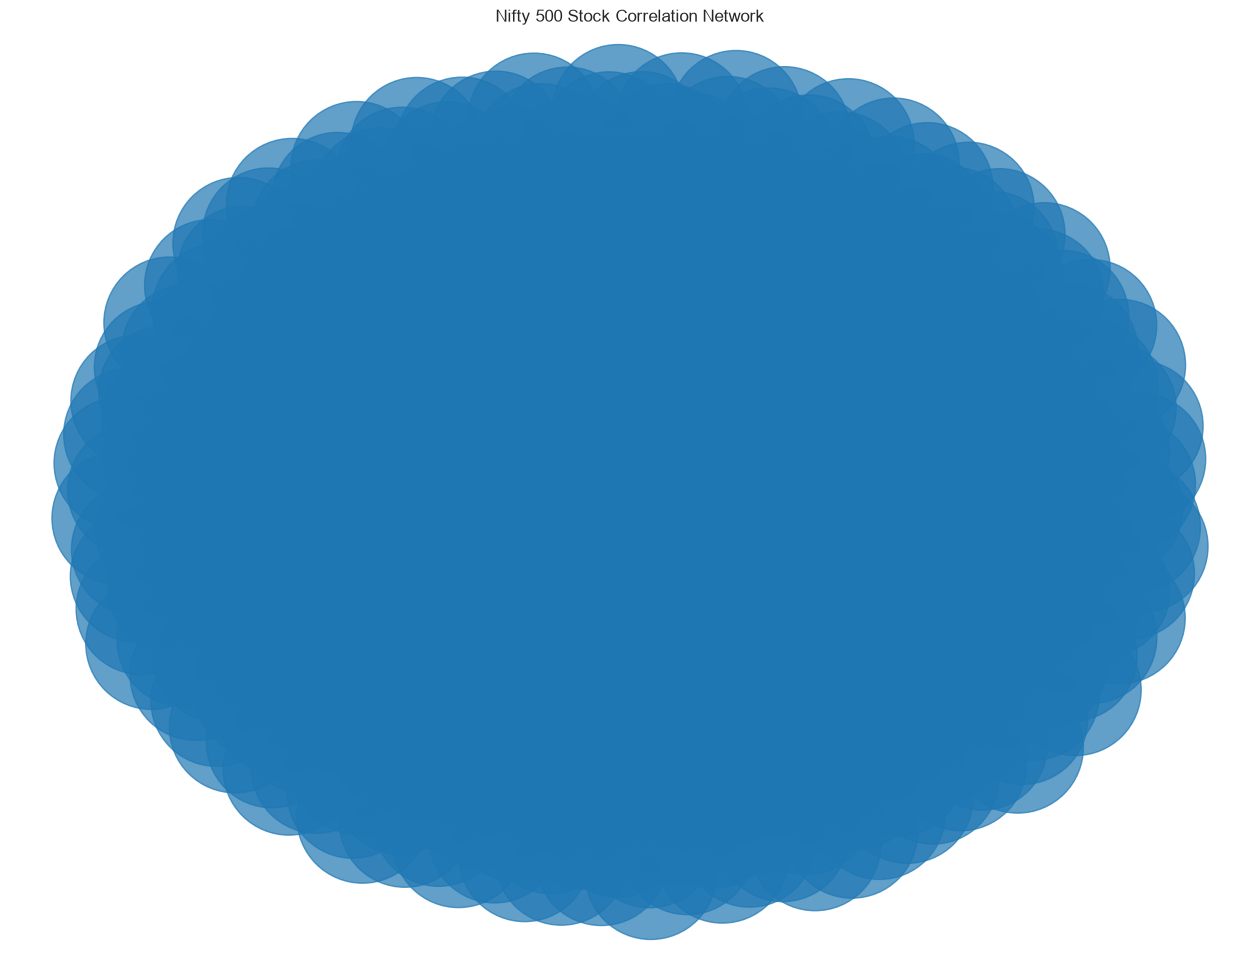

In [38]:
adjacency_matrix = pd.read_csv("unweighted_adjacency_matrix.csv", index_col=0)
G = nx.from_pandas_adjacency(adjacency_matrix)
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42, k=0.3)

degrees = dict(G.degree())
node_sizes = [degrees[node] * 20 + 20 for node in G.nodes()]

nx.draw_networkx(
    G,
    pos,
    node_size=node_sizes,
    with_labels=False,
    width=0.3,
    alpha=0.7
)

plt.title("Nifty 500 Stock Correlation Network")
plt.axis("off")
plt.show()

## A. Degree Distribution Plot & Interpretation

In [39]:
# Calculate degree of every stock
degrees = dict(G.degree())

degree_values = list(degrees.values())

# Display degree statistics
degree_df = pd.DataFrame({
    'Stock': list(degrees.keys()),
    'Degree': degree_values
})

print(degree_df.sort_values(by='Degree', ascending=False).head(10))
print(degree_df['Degree'].describe())

           Stock  Degree
0      360ONE.NS     446
1   AADHARHFC.NS     446
2    AARTIIND.NS     446
3       AAVAS.NS     446
4         ABB.NS     446
5  ABBOTINDIA.NS     446
6   ABCAPITAL.NS     446
7       ABREL.NS     446
8     ABSLAMC.NS     446
9         ACC.NS     446
count    447.0
mean     446.0
std        0.0
min      446.0
25%      446.0
50%      446.0
75%      446.0
max      446.0
Name: Degree, dtype: float64


In [40]:
sns.set_theme(style="whitegrid", context="notebook")

degrees = dict(G.degree())

degree_df = pd.DataFrame({
    'Stock': list(degrees.keys()),
    'Degree': list(degrees.values())
})

print(degree_df.sort_values('Degree', ascending=False).head(10))

           Stock  Degree
0      360ONE.NS     446
1   AADHARHFC.NS     446
2    AARTIIND.NS     446
3       AAVAS.NS     446
4         ABB.NS     446
5  ABBOTINDIA.NS     446
6   ABCAPITAL.NS     446
7       ABREL.NS     446
8     ABSLAMC.NS     446
9         ACC.NS     446


In [41]:
# gives the 15 stocks with the highest degree in the network
degree_df.sort_values(
    by='Degree',
    ascending=False
).head(15)

,Stock,Degree
0,360ONE.NS,446
1,AADHARHFC.NS,446
2,AARTIIND.NS,446
3,AAVAS.NS,446
4,ABB.NS,446
5,ABBOTINDIA.NS,446
6,ABCAPITAL.NS,446
7,ABREL.NS,446
8,ABSLAMC.NS,446
9,ACC.NS,446


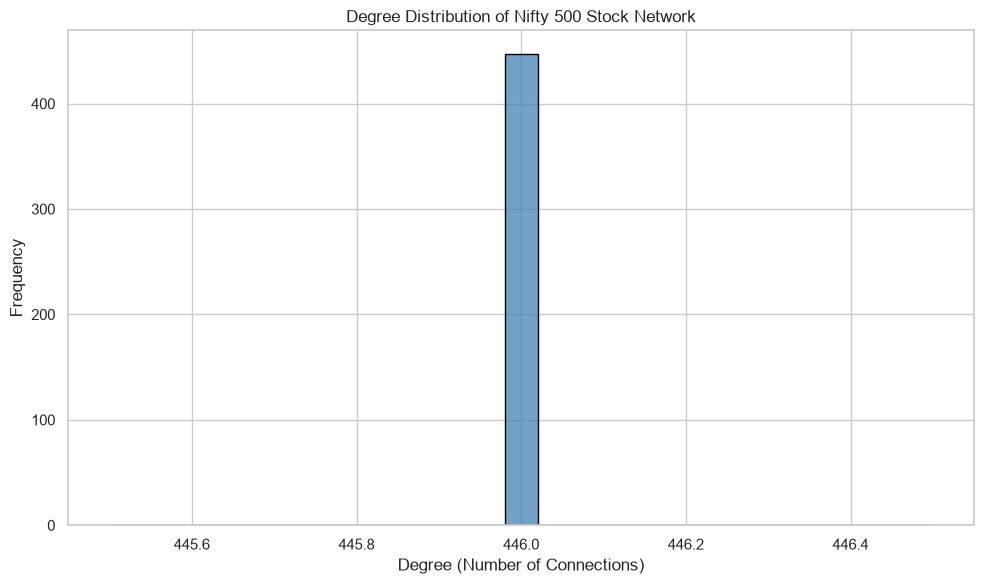

In [42]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=degree_df,
    x='Degree',
    bins=25,
    color='steelblue',
    edgecolor='black'
)

plt.title('Degree Distribution of Nifty 500 Stock Network')
plt.xlabel('Degree (Number of Connections)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

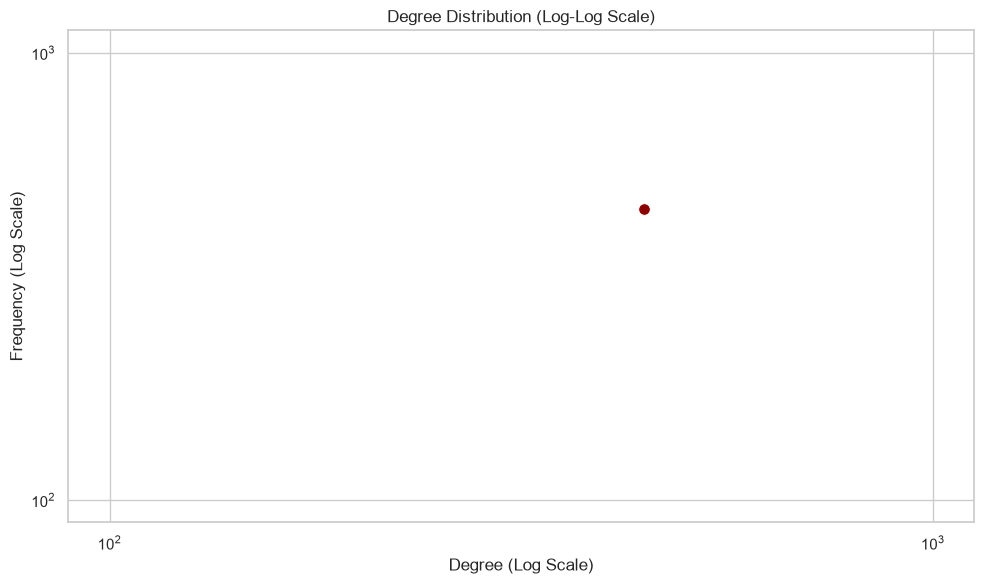

In [43]:
degree_counts = degree_df['Degree'].value_counts().sort_index()

# Remove degree zero and frequencies that cannot appear on a log scale
degree_counts = degree_counts[degree_counts.index > 0]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=degree_counts.index,
    y=degree_counts.values,
    color='darkred',
    s=70
)

plt.xscale('log')
plt.yscale('log')

plt.title('Degree Distribution (Log-Log Scale)')
plt.xlabel('Degree (Log Scale)')
plt.ylabel('Frequency (Log Scale)')

plt.tight_layout()
plt.show()

## B. Top-10 Centrality Leaderboard (The "Who's Who" of the Market)

In [44]:
# 1. Degree Centrality
degree_centrality = nx.degree_centrality(G)

# 2. Betweenness Centrality
betweenness_centrality = nx.betweenness_centrality(G)

# 3. Eigenvector Centrality
eigenvector_centrality = nx.eigenvector_centrality(
    G, max_iter=1000, tol=1e-06
)

In [45]:
# Create a centrality leaderboard
centrality_df = pd.DataFrame({
    'Stock': list(G.nodes()),
    'Degree Centrality': [degree_centrality[node] for node in G.nodes()],
    'Betweenness Centrality': [betweenness_centrality[node] for node in G.nodes()],
    'Eigenvector Centrality': [eigenvector_centrality[node] for node in G.nodes()]
})

print(centrality_df.head())

          Stock  Degree Centrality  Betweenness Centrality  \
0     360ONE.NS                1.0                     0.0   
1  AADHARHFC.NS                1.0                     0.0   
2   AARTIIND.NS                1.0                     0.0   
3      AAVAS.NS                1.0                     0.0   
4        ABB.NS                1.0                     0.0   

   Eigenvector Centrality  
0                0.047298  
1                0.047298  
2                0.047298  
3                0.047298  
4                0.047298  


In [46]:
# Get the Top 10 stocks for each measure
# Top 10 by Degree Centrality
top_degree = centrality_df.sort_values(
    by='Degree Centrality', ascending=False
).head(10)

# Top 10 by Betweenness Centrality
top_betweenness = centrality_df.sort_values(
    by='Betweenness Centrality', ascending=False
).head(10)

# Top 10 by Eigenvector Centrality
top_eigenvector = centrality_df.sort_values(
    by='Eigenvector Centrality', ascending=False
).head(10)

print("TOP 10 - DEGREE CENTRALITY")
print(top_degree.to_string(index=False))

print("\nTOP 10 - BETWEENNESS CENTRALITY")
print(top_betweenness.to_string(index=False))

print("\nTOP 10 - EIGENVECTOR CENTRALITY")
print(top_eigenvector.to_string(index=False))

TOP 10 - DEGREE CENTRALITY
        Stock  Degree Centrality  Betweenness Centrality  Eigenvector Centrality
    360ONE.NS                1.0                     0.0                0.047298
 AADHARHFC.NS                1.0                     0.0                0.047298
  AARTIIND.NS                1.0                     0.0                0.047298
     AAVAS.NS                1.0                     0.0                0.047298
       ABB.NS                1.0                     0.0                0.047298
ABBOTINDIA.NS                1.0                     0.0                0.047298
 ABCAPITAL.NS                1.0                     0.0                0.047298
     ABREL.NS                1.0                     0.0                0.047298
   ABSLAMC.NS                1.0                     0.0                0.047298
       ACC.NS                1.0                     0.0                0.047298

TOP 10 - BETWEENNESS CENTRALITY
        Stock  Degree Centrality  Betweenness Cen

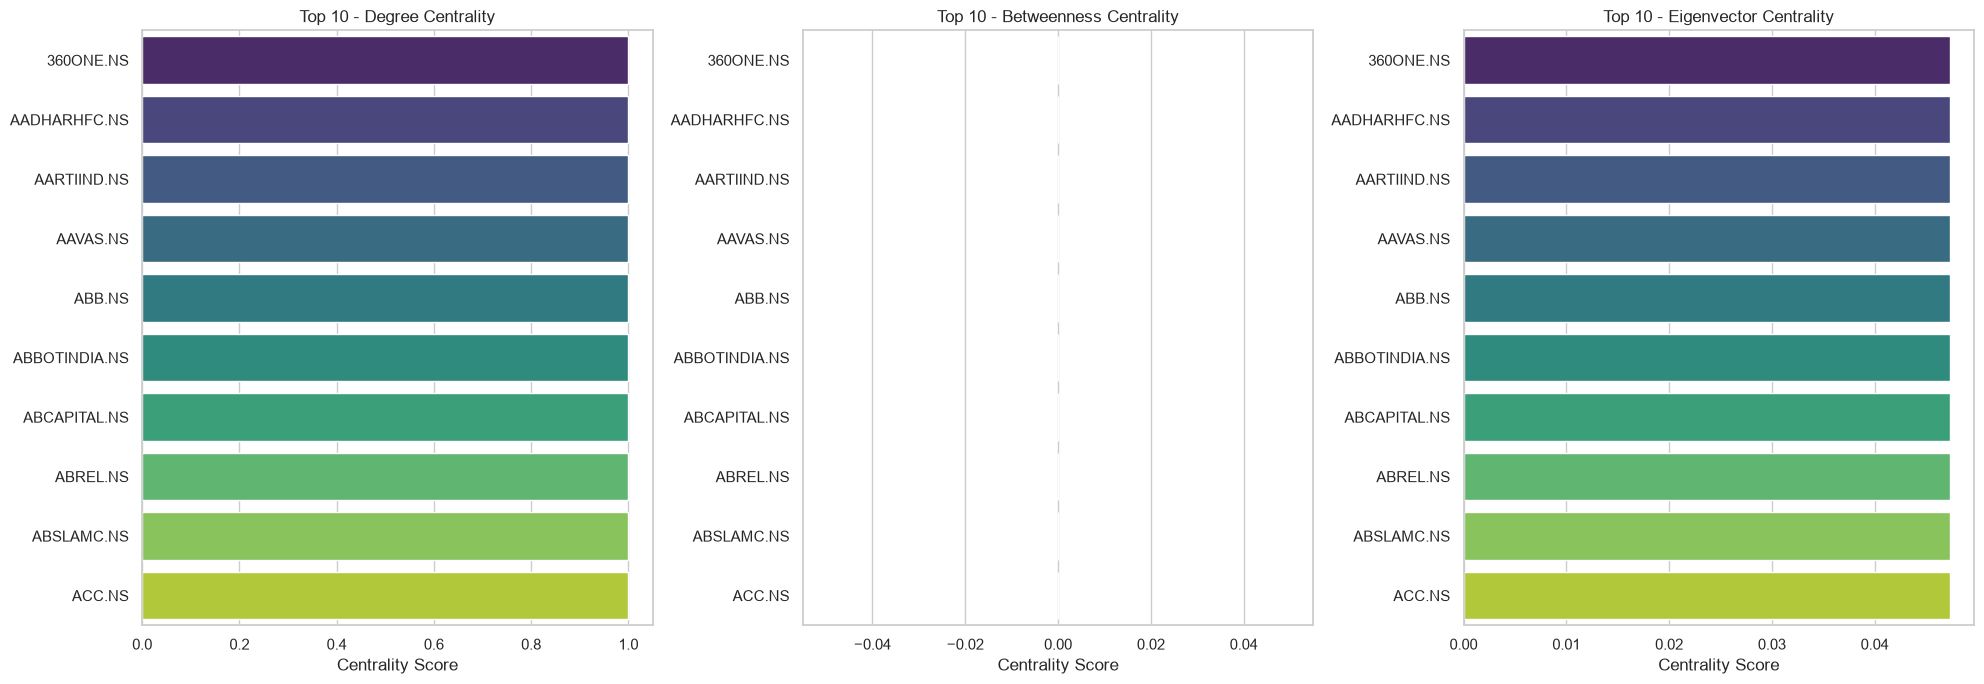

In [47]:
# Visualise the Top 10 leaderboard 
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

centralities = [
    (top_degree, 'Degree Centrality', 'Top 10 - Degree Centrality'),
    (top_betweenness, 'Betweenness Centrality', 'Top 10 - Betweenness Centrality'),
    (top_eigenvector, 'Eigenvector Centrality', 'Top 10 - Eigenvector Centrality')
]

for ax, (data, column, title) in zip(axes, centralities):
    sns.barplot(
        data=data,
        x=column,
        y='Stock',
        hue='Stock',
        palette='viridis',
        legend=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Centrality Score')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

## C. Local Clustering Coefficient & Sector Homophily

In [48]:
# Average clustering coefficient of the entire network
avg_clustering = nx.average_clustering(G)

print("Average Clustering Coefficient:", avg_clustering)

Average Clustering Coefficient: 1.0


In [49]:
# Calculate individual stock clustering coefficients
clustering_coefficients = nx.clustering(G)

clustering_df = pd.DataFrame({
    'Stock': list(clustering_coefficients.keys()),
    'Clustering Coefficient': list(clustering_coefficients.values())
})

# Sort stocks by clustering coefficient
clustering_df = clustering_df.sort_values(
    by='Clustering Coefficient',
    ascending=False
)

print(clustering_df.head(15))

            Stock  Clustering Coefficient
0       360ONE.NS                     1.0
1    AADHARHFC.NS                     1.0
2     AARTIIND.NS                     1.0
3        AAVAS.NS                     1.0
4          ABB.NS                     1.0
5   ABBOTINDIA.NS                     1.0
6    ABCAPITAL.NS                     1.0
7        ABREL.NS                     1.0
8      ABSLAMC.NS                     1.0
9          ACC.NS                     1.0
10         ACE.NS                     1.0
11     ACUTAAS.NS                     1.0
12  ADANIENSOL.NS                     1.0
13    ADANIENT.NS                     1.0
14  ADANIGREEN.NS                     1.0


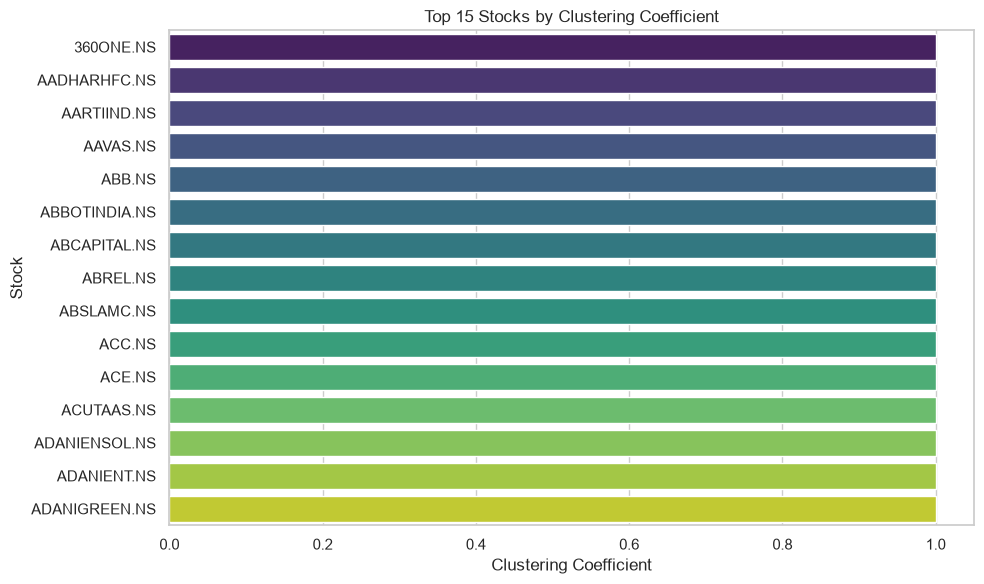

In [50]:
# Visualise the top 15 stocks
plt.figure(figsize=(10, 6))

sns.barplot(
    data=clustering_df.head(15),
    x='Clustering Coefficient',
    y='Stock',
    hue='Stock',
    palette='viridis',
    legend=False
)

plt.title('Top 15 Stocks by Clustering Coefficient')
plt.tight_layout()
plt.show()

### Sector homophily - Are stocks more likely to be connected to other stocks belonging to the same industry?

In [51]:
# Download and save adjusted close prices for a list of tickers for nifty500 stocks from Yahoo Finance
url = "https://nsearchives.nseindia.com/content/indices/ind_nifty500list.csv"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

nifty500 = pd.read_csv(StringIO(response.text))


In [52]:
print(nifty500.columns)

Index(['Company Name', 'Industry', 'Symbol', 'Series', 'ISIN Code'], dtype='str')


In [53]:
# Create ticker names matching your graph nodes
nifty500['Ticker'] = nifty500['Symbol'] + '.NS'

# Create sector mapping
sector_map = dict(zip(
    nifty500['Ticker'],
    nifty500['Industry']
))

In [54]:
# Assign sectors to your NetworkX graph
for stock in G.nodes():
    G.nodes[stock]['sector'] = sector_map.get(stock, 'Unknown')

In [55]:
print(pd.Series(
    nx.get_node_attributes(G, 'sector')
).value_counts())

Financial Services                   90
Capital Goods                        63
Healthcare                           39
Automobile and Auto Components       35
Fast Moving Consumer Goods           27
Chemicals                            26
Information Technology               21
Metals & Mining                      17
Oil Gas & Consumable Fuels           16
Power                                15
Consumer Durables                    15
Consumer Services                    15
Realty                               13
Services                             12
Construction                         12
Telecommunication                    11
Construction Materials               10
Textiles                              5
Media Entertainment & Publication     4
Diversified                           1
Name: count, dtype: int64


In [56]:
sector_assortativity = nx.attribute_assortativity_coefficient(
    G, 'sector'
)

print("Sector Homophily:", sector_assortativity)

Sector Homophily: -0.00224215246636772


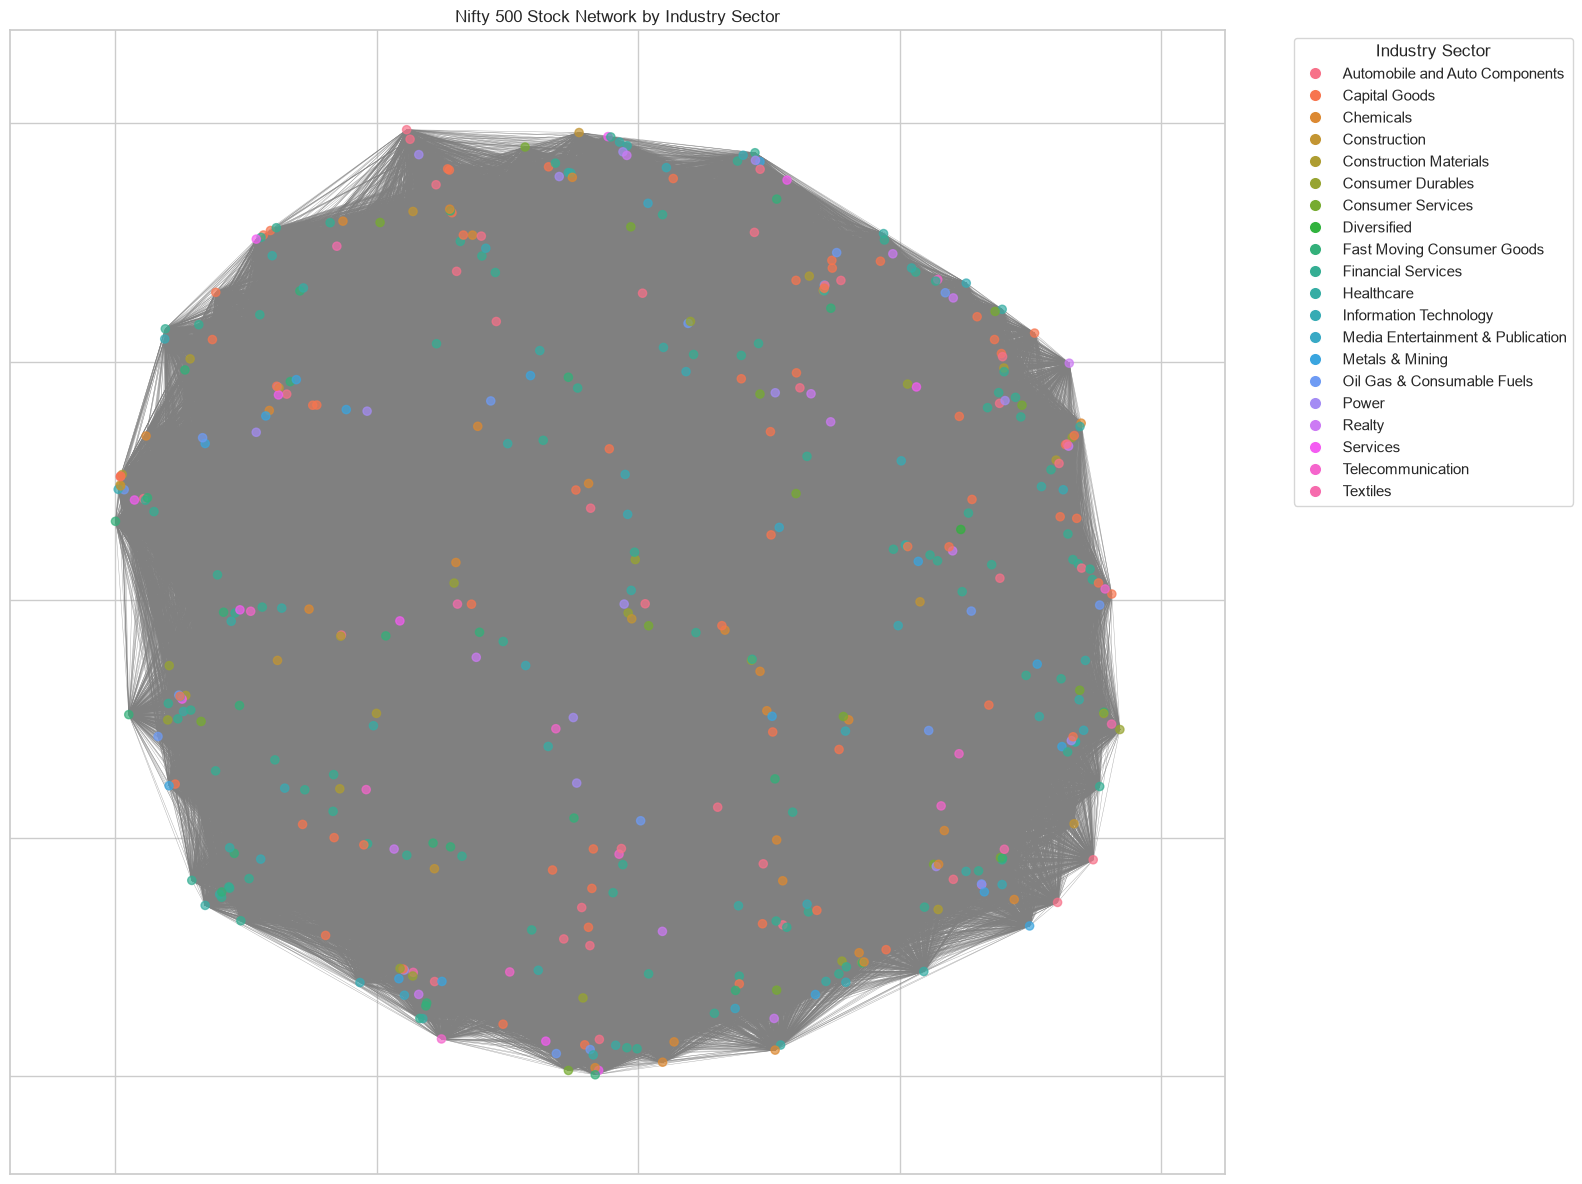

In [57]:
plt.figure(figsize=(16, 12))

pos = nx.spring_layout(G, seed=42)

sectors = nx.get_node_attributes(G, 'sector')
unique_sectors = sorted(set(sectors.values()))

palette = sns.color_palette('husl', len(unique_sectors))
sector_colors = dict(zip(unique_sectors, palette))

node_colors = [sector_colors[sectors[node]] for node in G.nodes()]

nx.draw_networkx(
    G,
    pos,
    node_color=node_colors,
    node_size=35,
    with_labels=False,
    edge_color='gray',
    alpha=0.7,
    width=0.3
)
# Create legend handles
handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=color, markersize=9, label=sector)
    for sector, color in sector_colors.items()
]

plt.legend(handles=handles, title="Industry Sector",
           bbox_to_anchor=(1.05, 1), loc='upper left')

plt.title('Nifty 500 Stock Network by Industry Sector')
plt.tight_layout()

plt.show()


# plt.axis('off')
# plt.show()